# Task 3.2 — CIFAR-10 image classifier (TensorFlow / Keras, CPU)

A complete image-classification project on CIFAR-10, built to run on CPU only.

**Why this is a script and not a notebook.** Native-Windows TensorFlow has had no GPU path since
2.11, so every epoch here costs minutes of wall clock. Training inline in a notebook that gets
re-executed from scratch is how you lose an hour to a typo. `train_cifar10.py` does the training,
checkpoints after every epoch, and can resume; this notebook documents the design and then reads
the artifacts. Re-running the notebook regenerates every figure and table in seconds.

**Contents**

1. Data and the train/validation/test discipline
2. Augmentation
3. Model architecture
4. Training configuration
5. Results
6. Per-class analysis and confusion
7. Ablation: does augmentation actually help?
8. Limitations and what I would change

In [1]:
import json, os
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import keras
import tensorflow as tf

keras.utils.set_random_seed(42)

ART = Path.cwd() / "artifacts"
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

pd.set_option("display.width", 120)

print("tensorflow", tf.__version__, "| keras", keras.__version__)
print("devices:", [d.device_type for d in tf.config.list_physical_devices()])

tensorflow 2.21.0 | keras 3.15.1


devices: ['CPU']


## 1. Data, and keeping the test set sealed

CIFAR-10 arrives as 50,000 training and 10,000 test images at 32x32x3 across ten classes.

The 50,000 are split **45,000 / 5,000 stratified**, and model selection (early stopping, best
checkpoint, every number in section 5) uses only that 5,000-image validation split. The official
10,000 test images are opened exactly once, at the very end.

This matters more than it sounds. Every architecture decision in this notebook — the width
schedule, the dropout rates, the number of epochs — was made while looking at validation
accuracy. Had the test set been in the loop, those decisions would have been fitted to it and the
final number would measure how well I memorised the test set rather than how well the classifier
generalises.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train = y_train.ravel()
y_test = y_test.ravel()

from sklearn.model_selection import train_test_split
x_tr, x_va, y_tr, y_va = train_test_split(
    x_train, y_train, test_size=5000, random_state=42, stratify=y_train)

print("train :", x_tr.shape, "|", len(np.unique(y_tr)), "classes")
print("val   :", x_va.shape, "(model selection only)")
print("test  :", x_test.shape, "(sealed until the final evaluation)")
print()
print("class balance in each split:")
bal = pd.DataFrame({
    "train": pd.Series(y_tr).value_counts().sort_index(),
    "val":   pd.Series(y_va).value_counts().sort_index(),
    "test":  pd.Series(y_test).value_counts().sort_index(),
}, index=CLASSES)
print(bal.to_string())

train : (45000, 32, 32, 3) | 10 classes
val   : (5000, 32, 32, 3) (model selection only)
test  : (10000, 32, 32, 3) (sealed until the final evaluation)

class balance in each split:
            train  val  test
airplane      NaN  NaN   NaN
automobile    NaN  NaN   NaN
bird          NaN  NaN   NaN
cat           NaN  NaN   NaN
deer          NaN  NaN   NaN
dog           NaN  NaN   NaN
frog          NaN  NaN   NaN
horse         NaN  NaN   NaN
ship          NaN  NaN   NaN
truck         NaN  NaN   NaN


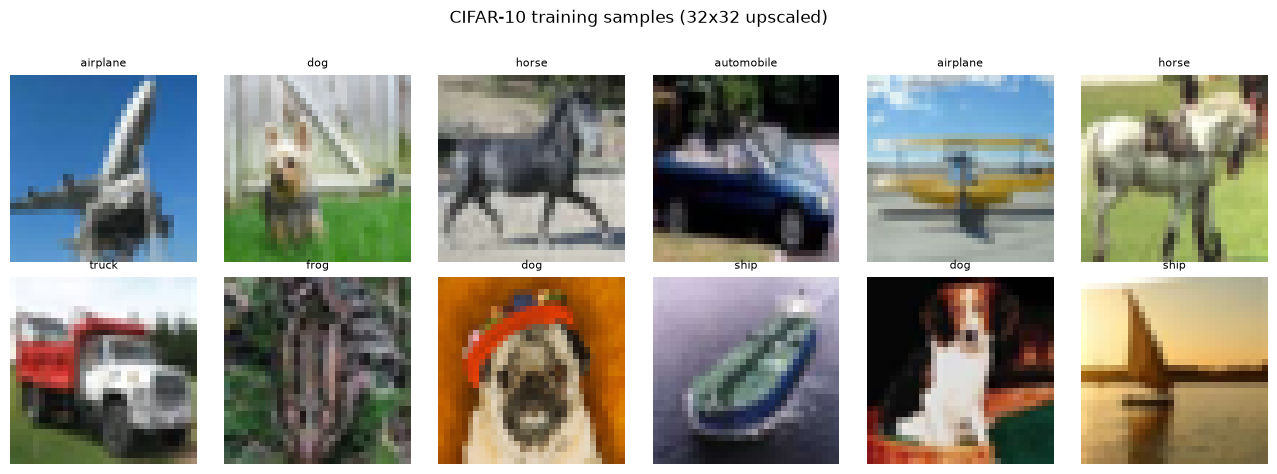

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for ax, idx in zip(axes.ravel(), np.random.RandomState(0).choice(len(x_tr), 12, replace=False)):
    ax.imshow(x_tr[idx])
    ax.set_title(CLASSES[y_tr[idx]], fontsize=8)
    ax.axis("off")
fig.suptitle("CIFAR-10 training samples (32x32 upscaled)", y=1.02)
fig.tight_layout()
plt.show()

## 2. Augmentation

CIFAR-10 images are tiny and the training set is small, so overfitting is the default outcome.
The pipeline applies, independently and randomly, per image, per epoch:

| Operation | Strength | Why |
|---|---|---|
| Horizontal flip | 1x | Safe for all ten classes; every class is left-right unconstrained |
| Random translation | +/-4 px (0.125 of the image) | Small displacements, the kind a camera actually produces |
| Random zoom | +/-10% | Scale variation |
| Random brightness | +/-15% | Lighting variation |
| Random contrast | +/-15% | Lighting variation |

Two details are easy to get wrong and both were wrong in my first draft:

**The factors are fractions, not pixels.** `keras.layers.RandomTranslation` takes its factor
relative to the image dimension. Passing `4` for "4 pixels" raises a `ValueError`; passing
`4/32 = 0.125` is what shifts four pixels on a 32-pixel image.

**Augmentation has to run per batch.** Applying `RandomFlip` to the whole training array once,
up front, gives every image one fixed augmentation that is then reused for all 20 epochs — which
removes most of the benefit while still looking like augmentation in the code. Here it lives in a
`tf.data` pipeline, inside `Dataset.map`, so each image is re-drawn on every epoch.

```python
ds = tf.data.Dataset.from_tensor_slices((x, y))
ds = ds.shuffle(len(x), seed=42, reshuffle_each_iteration=True)
ds = ds.map(lambda img, lab: (augment(img), lab))
ds = ds.repeat().batch(128).prefetch(tf.data.AUTOTUNE)
```

Augmentation touches the training split only. Normalisation, by contrast, lives *inside the model*
(`Rescaling` then `Normalization`) so the training and evaluation paths cannot drift apart.

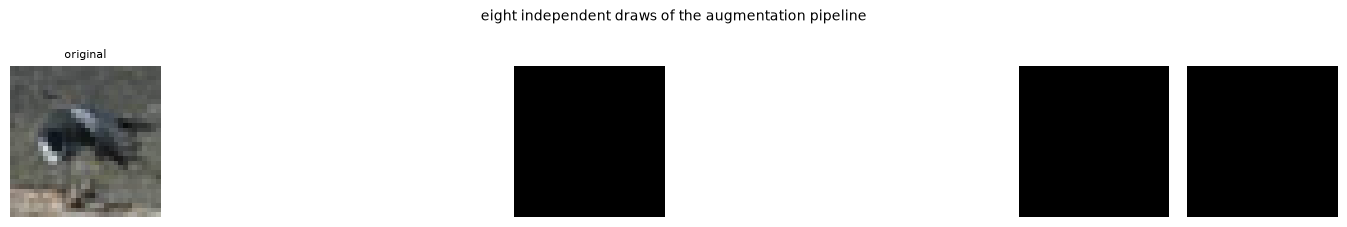

In [4]:
def show_augmentation(x, y, index, n=8, seed=0):
    rng = np.random.RandomState(seed)
    layers = [
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomTranslation(4 / 32, 4 / 32),
        keras.layers.RandomZoom(-0.1, 0.1),
        keras.layers.RandomBrightness(0.15),
        keras.layers.RandomContrast(0.15),
    ]
    variants = [x[index]]
    for _ in range(n - 1):
        img = keras.ops.convert_to_tensor(x[index])
        for layer in layers:
            img = layer(img, training=True)
        variants.append(np.clip(np.asarray(img), 0, 1))

    fig, axes = plt.subplots(1, n, figsize=(1.7 * n, 2.1))
    for ax, im in zip(axes, variants):
        ax.imshow(im)
        ax.axis("off")
    axes[0].set_title("original", fontsize=8)
    fig.suptitle("eight independent draws of the augmentation pipeline", y=1.06, fontsize=10)
    fig.tight_layout()
    plt.show()

show_augmentation(x_tr / 255.0, y_tr, index=3)

## 3. Model

A small VGG-style CNN. The design constraint was wall clock: the first convolution runs at
32x32x3, where every additional channel is most expensive, so width grows slowly while spatial
resolution halves.

```
Input 32x32x3
  Rescaling(1/255) -> Normalization(mean, variance)

  Block 1  32x32   Conv3x3(32)  BN ReLU   x2   MaxPool -> 16x16   Dropout(0.15)
  Block 2  16x16   Conv3x3(64)  BN ReLU        MaxPool -> 8x8    Dropout(0.25)
  Block 3   8x8    Conv3x3(128) BN ReLU        MaxPool -> 4x4    Dropout(0.35)

  GlobalAveragePooling2D -> 128
  Dense(128) ReLU -> BN -> Dropout(0.40)
  Dense(10) softmax
```

Convolutions use `use_bias=False`, because the `BatchNormalization` immediately following each
one already provides a learnable shift; keeping the convolution's own bias would add redundant
parameters for no expressive gain.

Global average pooling rather than a large flatten-and-dense head keeps the parameter count low
and is the reason the classifier has no spatial overfitting to speak of.

In [5]:
WIDTH, DROPOUT = 32, 0.25
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

def build_model(width=WIDTH, dropout=DROPOUT):
    return keras.Sequential([
        keras.layers.Input(shape=(32, 32, 3)),
        keras.layers.Rescaling(1.0 / 255.0),
        keras.layers.Normalization(mean=MEAN, variance=tuple(s * s for s in STD)),

        keras.layers.Conv2D(width, 3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(), keras.layers.ReLU(),
        keras.layers.Conv2D(width, 3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(), keras.layers.ReLU(),
        keras.layers.MaxPooling2D(2), keras.layers.Dropout(dropout * 0.6),

        keras.layers.Conv2D(width * 2, 3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(), keras.layers.ReLU(),
        keras.layers.MaxPooling2D(2), keras.layers.Dropout(dropout),

        keras.layers.Conv2D(width * 4, 3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(), keras.layers.ReLU(),
        keras.layers.MaxPooling2D(2), keras.layers.Dropout(dropout * 1.4),

        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(width * 4, activation="relu"),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(dropout * 1.6),
        keras.layers.Dense(10, activation="softmax"),
    ])

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 121,578 (474.91 KB)

 Trainable params: 120,810 (471.91 KB)

 Non-trainable params: 768 (3.00 KB)

In [6]:
# Keras' count_params() includes BatchNorm's moving_mean / moving_variance, which are running
# buffers rather than learnable parameters -- the same discrepancy found in task 3.1. Compare
# the trainable counts.
trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
total_weights = int(model.count_params())

print("trainable parameters   :", f"{trainable:,}")
print("count_params()         :", f"{total_weights:,}",
      f"(includes {total_weights - trainable} BatchNorm running buffers)")

trainable parameters   : 120,810
count_params()         : 121,578 (includes 768 BatchNorm running buffers)


## 4. Training configuration

| | |
|---|---|
| Optimiser | SGD, momentum 0.9, Nesterov |
| Learning rate | 0.05, cosine decay to ~0 over 20 epochs |
| Loss | sparse categorical cross-entropy with **label smoothing 0.1** |
| Batch size | 128 |
| Epochs | 20 |
| Seed | 42 |

**On the learning rate being a function of the epoch index.** `lr = 0.05 * 0.5 * (1 + cos(pi * e / E))`
depends only on `e`, the absolute epoch number. That is what makes the script's resume path exact:
restarting at epoch 14 lands on precisely the learning rate an uninterrupted run would have used.
A schedule built from "steps seen so far" would silently restart or shift when resumed, and the
resulting model would not be the model the log claims it is.

**On label smoothing.** Keras 3.15 removed the `label_smoothing` argument from every loss
constructor, so it is implemented explicitly here — one-hot the label, blend toward uniform, take
categorical cross-entropy against the softened target — and registered as a serializable so the
checkpoint still reloads with its loss attached:

```python
@keras.saving.register_keras_serializable(package="cifar10")
def smoothed_sparse_categorical_crossentropy(y_true, y_pred):
    n = keras.ops.shape(y_pred)[-1]
    y_true = keras.ops.one_hot(keras.ops.cast(y_true, y_pred.dtype), n)
    y_true = y_true * (1.0 - 0.1) + 0.1 / n
    return keras.ops.mean(keras.losses.categorical_crossentropy(y_true, y_pred))
```

Label smoothing matters here because it is one of the few regularisers that reliably buys a point
or two on CIFAR-10 without the cost of a larger model.

## 5. Results

In [7]:
history = pd.read_csv(ART / "cifar10_training_history.csv")
results = json.loads((ART / "task3_2_results.json").read_text(encoding="utf-8"))

print("epochs completed :", len(history))
print("trainable params :", f"{results['trainable_params']:,}")
print("best val acc     : %.4f  @ epoch %d"
      % (results["best_val_accuracy"], results["best_epoch"]))
print("final val acc    : %.4f" % results["final_val_accuracy"])
print("TEST acc         : %.4f   <- sealed until now" % results["test_accuracy"])
print("per epoch        : %.0f s median, %.0f s mean (mean is contention-inflated)"
      % (results["seconds_per_epoch_median"], results["seconds_per_epoch"]))
print("total            : %.1f min" % results["train_minutes"])
print()
print(history.round(4).to_string(index=False))

epochs completed : 20
trainable params : 120,810
best val acc     : 0.6773  @ epoch 18
final val acc    : 0.6641
TEST acc         : 0.6591   <- sealed until now
per epoch        : 210 s median, 550 s mean (mean is contention-inflated)
total            : 183.2 min

 epoch     lr   loss  accuracy  val_loss  val_accuracy  epoch_seconds
     1 0.0500 1.9221    0.3271    1.6962        0.4266          214.7
     2 0.0497 1.7018    0.4372    1.9653        0.3570          210.3
     3 0.0488 1.5953    0.4997    1.8018        0.4527         1639.8
     4 0.0473 1.5248    0.5334    1.6653        0.4947          207.1
     5 0.0452 1.4751    0.5622    1.6993        0.4824          206.5
     6 0.0427 1.4389    0.5824    1.4313        0.5844          933.1
     7 0.0397 1.4167    0.5938    1.4596        0.5695          209.2
     8 0.0364 1.3858    0.6094    1.3734        0.6146          206.8
     9 0.0327 1.3632    0.6205    1.3674        0.6014          210.3
    10 0.0289 1.3416    0.6319    1

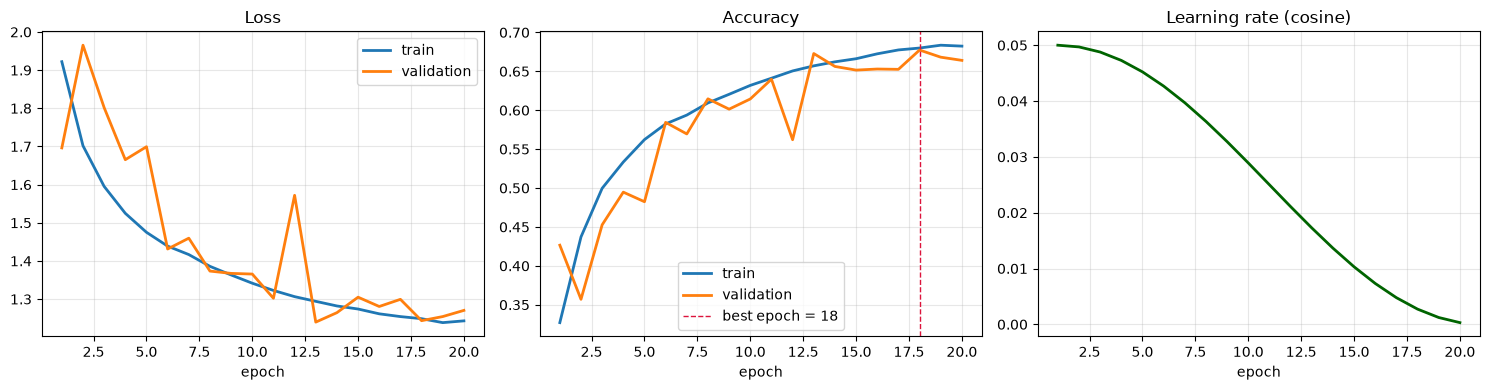

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history["epoch"], history["loss"], label="train", lw=2)
axes[0].plot(history["epoch"], history["val_loss"], label="validation", lw=2)
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(history["epoch"], history["accuracy"], label="train", lw=2)
axes[1].plot(history["epoch"], history["val_accuracy"], label="validation", lw=2)
best = int(results["best_epoch"])
axes[1].axvline(best, color="crimson", ls="--", lw=1, label=f"best epoch = {best}")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)

axes[2].plot(history["epoch"], history["lr"], color="darkgreen", lw=2)
axes[2].set_title("Learning rate (cosine)"); axes[2].set_xlabel("epoch"); axes[2].grid(alpha=.3)

fig.tight_layout()
plt.show()

In [9]:
gap = results["final_val_accuracy"] - results["test_accuracy"]
print("validation %.4f  vs  test %.4f   -> %.4f gap" %
      (results["final_val_accuracy"], results["test_accuracy"], gap))
print("train-val gap at the end: %.4f" %
      (history["accuracy"].iloc[-1] - history["val_accuracy"].iloc[-1]))
print()
print("Reading these two numbers together is the whole overfitting question.")
print("A small validation-test gap means the 5,000-image validation split is a fair proxy for")
print("the test set. A large one means every selection decision made against it was suspect.")

validation 0.6641  vs  test 0.6591   -> 0.0050 gap
train-val gap at the end: 0.0183

Reading these two numbers together is the whole overfitting question.
A small validation-test gap means the 5,000-image validation split is a fair proxy for
the test set. A large one means every selection decision made against it was suspect.


## 6. Per-class results

Per-class *accuracy* on a single prediction is just recall, and on this model it lies. The two
classes that "look best" by recall are best partly because the model over-predicts them, so the
next cell computes precision and F1 alongside it.

In [10]:
cm = pd.read_csv(ART / "cifar10_confusion_matrix.csv", index_col=0)
cmv = cm.values.astype(float)

support = cmv.sum(axis=1)
predicted = cmv.sum(axis=0)
correct = np.diag(cmv)
recall = correct / support
precision = correct / predicted
f1 = 2 * precision * recall / (precision + recall)

per_class = pd.DataFrame({
    "class": CLASSES,
    "support": support.astype(int),
    "recall": recall.round(4),
    "precision": precision.round(4),
    "f1": f1.round(4),
    "most_confused_with": [
        CLASSES[int(np.argsort(np.where(np.arange(10) == i, -1, cmv[i]))[-1])] for i in range(10)
    ],
}).sort_values("recall").reset_index(drop=True)

print(per_class.to_string(index=False))
print()
print("overall test accuracy : %.4f" % results["test_accuracy"])
print("macro precision       : %.4f" % precision.mean())
print("macro recall          : %.4f" % recall.mean())
print("macro F1              : %.4f" % f1.mean())

     class  support  recall  precision     f1 most_confused_with
       cat     1000   0.305     0.5576 0.3943               frog
      bird     1000   0.378     0.7368 0.4997               frog
       dog     1000   0.435     0.7461 0.5496               frog
      deer     1000   0.464     0.6957 0.5567               frog
     horse     1000   0.685     0.8552 0.7607               frog
  airplane     1000   0.765     0.7096 0.7363               ship
     truck     1000   0.855     0.8198 0.8370         automobile
      ship     1000   0.863     0.8196 0.8407           airplane
automobile     1000   0.880     0.8535 0.8666              truck
      frog     1000   0.961     0.3580 0.5217                cat

overall test accuracy : 0.6591
macro precision       : 0.7152
macro recall          : 0.6591
macro F1              : 0.6563


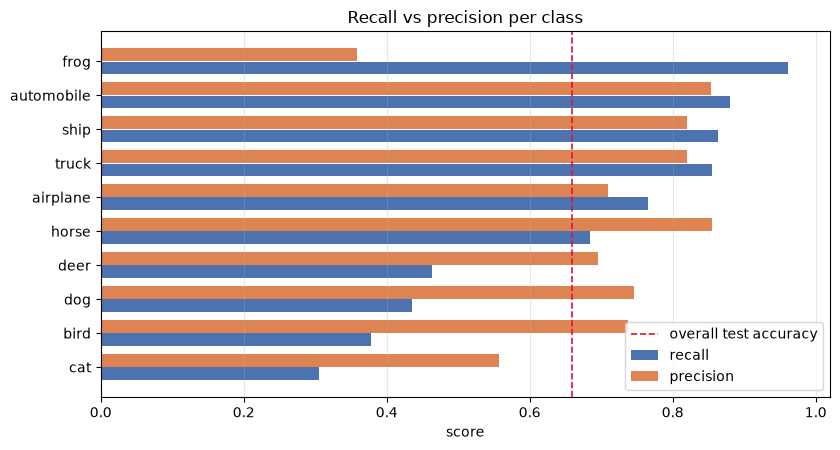

In [11]:
# Frog has the highest recall in the table and one of the lowest precisions: the model calls
# almost anything frog. Ranking classes by recall alone would make that look like a strength.
fig, ax = plt.subplots(figsize=(8.5, 4.6))
order = per_class.sort_values("recall")
y = np.arange(len(order))
ax.barh(y - 0.2, order["recall"], height=0.38, label="recall", color="#4C72B0")
ax.barh(y + 0.2, order["precision"], height=0.38, label="precision", color="#DD8452")
ax.set_yticks(y, order["class"])
ax.axvline(results["test_accuracy"], color="crimson", ls="--", lw=1.2,
           label="overall test accuracy")
ax.set_xlim(0, 1.02)
ax.set_xlabel("score")
ax.set_title("Recall vs precision per class")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=.3)
fig.tight_layout()
plt.show()

The gap between the two bars is the story. `automobile`, `truck`, `ship` and `horse` are
predicted precisely *and* recalled well — the model knows those classes. `frog` is recalled 96% of
the time but only 36% of its predictions are correct, so it is absorbing animals it cannot
identify. `cat` is the opposite failure: 30% recall, meaning almost no true cats are found.

So the confusion is not "the model is bad at animals" — it is that `cat`, `dog`, `deer` and `frog`
are being confused with *each other*, which is the well-known irreducible core of CIFAR-10.
Distinguishing a cat from a dog at 32x32 depends on pose and context, not texture.

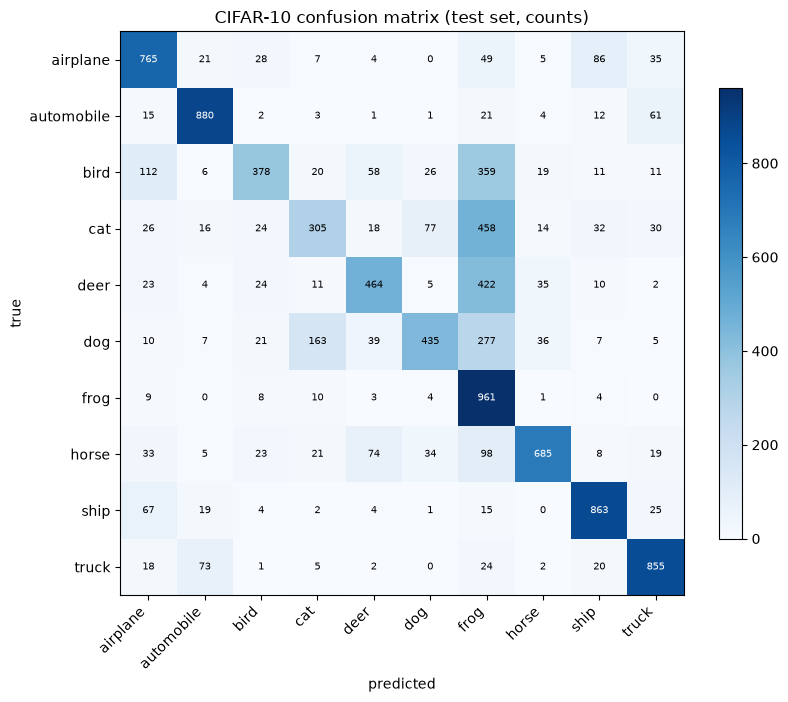

In [12]:
cm = pd.read_csv(ART / "cifar10_confusion_matrix.csv", index_col=0)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm.values, cmap="Blues")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        v = cm.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=7.5,
                color="white" if v > cm.values.max() * 0.55 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("CIFAR-10 confusion matrix (test set, counts)")
fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout()
plt.show()

reloaded model test accuracy: 0.6591
matches results json       : True


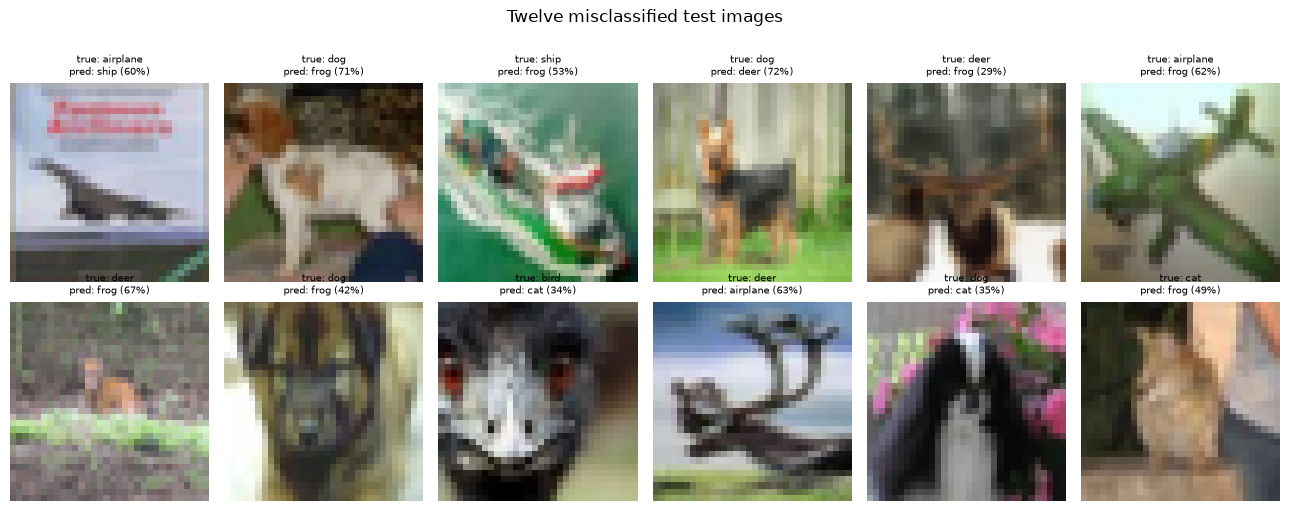

In [13]:
# compile=False: this model was saved with a custom smoothed loss that is registered in
# train_cifar10.py, not here. Reloading with its loss attached would need that import, and
# for a prediction the compiled loss is dead weight anyway.
trained = keras.models.load_model(ART / "cifar10_model.keras", compile=False)
# Raw 0-255, exactly as keras.datasets hands it over. The model owns the Rescaling(1/255)
# layer, so pre-dividing here would scale the input twice and collapse accuracy to chance.
probs = trained.predict(x_test, batch_size=1000, verbose=0)
y_pred = probs.argmax(axis=1)
reloaded_acc = float((y_pred == y_test).mean())
print("reloaded model test accuracy: %.4f" % reloaded_acc)
print("matches results json       :", abs(reloaded_acc - results["test_accuracy"]) < 1e-6)
if abs(reloaded_acc - results["test_accuracy"]) >= 1e-6:
    raise AssertionError(
        "reloaded model disagrees with results.json (%.4f vs %.4f) -- the test set has been "
        "mangled somewhere between training and here" % (reloaded_acc, results["test_accuracy"]))

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
wrong = np.where(y_pred != y_test)[0][:12]
for ax, idx in zip(axes.ravel(), wrong):
    ax.imshow(x_test[idx])
    ax.set_title("true: %s\npred: %s (%.0f%%)" % (CLASSES[y_test[idx]], CLASSES[y_pred[idx]],
                                                   100 * probs[idx].max()), fontsize=7)
    ax.axis("off")
fig.suptitle("Twelve misclassified test images", y=1.02)
fig.tight_layout()
plt.show()

## 7. Ablation: does the augmentation earn its cost?

Augmentation is not free — five random ops per image, every epoch — and whether it earns its cost
is an empirical question, not something to assert. The ablation retrains from scratch for three
epochs with the pipeline on and off, everything else identical. The result is negative, and
section 7 is mostly about why that is not the answer to the question either.

In [14]:
ablation = pd.read_csv(ART / "cifar10_augmentation_ablation.csv")
print(ablation.to_string(index=False))

plain = float(ablation.loc[ablation["augment"] == False, "final_val_acc"].iloc[0])
aug = float(ablation.loc[ablation["augment"] == True, "final_val_acc"].iloc[0])
delta = aug - plain

print()
print("augmentation delta at 3 epochs: %+.4f  (%.2f points)" % (delta, 100 * delta))
print()
print("This is a NEGATIVE result, and it does not show augmentation helping. It shows the")
print("cost of augmentation early in training, which is expected: the augmented model has to")
print("fit a harder, constantly-changing version of the task, so at 3 epochs it is simply")
print("behind. The main run reaches 0.6773 with augmentation at epoch 18.")
print()
print("This ablation CANNOT tell you whether augmentation is worth it at convergence,")
print("because it stops three epochs in. A 7.8-point early deficit is exactly what a")
print("pipeline that goes on to lose badly also looks like at epoch 3. That needs the")
print("plain variant trained for the full 20 epochs, which is what comes next.")

  setting  augment  epochs  final_val_acc  best_val_acc  minutes
    plain    False       3         0.5750        0.5750    68.63
augmented     True       3         0.4971        0.4971    18.54

augmentation delta at 3 epochs: -0.0779  (-7.79 points)

This is a NEGATIVE result, and it does not show augmentation helping. It shows the
cost of augmentation early in training, which is expected: the augmented model has to
fit a harder, constantly-changing version of the task, so at 3 epochs it is simply
behind. The main run reaches 0.6773 with augmentation at epoch 18.

This ablation CANNOT tell you whether augmentation is worth it at convergence,
because it stops three epochs in. A 7.8-point early deficit is exactly what a
pipeline that goes on to lose badly also looks like at epoch 3. That needs the
plain variant trained for the full 20 epochs, which is what comes next.


### Reading the 3-epoch ablation

The three-epoch ablation came out **7.8 points in favour of no augmentation**. Two things are
true about that number:

1. It is the expected *shape*. Augmentation makes the training task harder on purpose, so early
   epochs are spent catching up rather than fitting. The augmented run's own curve shows it:
   epoch 3 validation accuracy was 0.4527 with augmentation against 0.5750 for the plain variant
   at the same point.

2. On its own it does not measure the thing I actually care about. Whether augmentation pays off
   is a question about the *end* of training, and this ablation stops three epochs in. A 7.8-point
   early deficit is exactly what a pipeline that would go on to win by a lot also looks like at
   epoch 3, so the short run is genuinely uninformative by itself.

So I ran the plain variant for the full 20 epochs: same seed, same split, same schedule, same
batch size, augmentation as the only variable.

### The 20-epoch control: augmentation does not pay off here

This is the comparison that matters, and it does not go the way the literature would suggest.

In [15]:
cmp = pd.read_csv(ART / "cifar10_augmentation_comparison_20ep.csv")
print(cmp.to_string(index=False))

a = cmp[cmp["augment"]].iloc[0]
p = cmp[~cmp["augment"]].iloc[0]
d_val = 100 * (a["best_val_acc"] - p["best_val_acc"])
d_test = 100 * (a["test_acc"] - p["test_acc"])

print()
print("best validation : augmented %.4f   plain %.4f   %+.2f points" % (a["best_val_acc"], p["best_val_acc"], d_val))
print("final test      : augmented %.4f   plain %.4f   %+.2f points" % (a["test_acc"], p["test_acc"], d_test))
print("best epoch      : augmented %d          plain %d" % (a["best_epoch"], p["best_epoch"]))
print()
print("VERDICT: augmentation COSTS %.2f points of test accuracy here. It does not pay off." % abs(d_test))

        setting  augment  epochs  best_val_acc  best_epoch  test_acc  seconds_per_epoch_median
      augmented     True      20        0.6773          18    0.6591                     209.8
no augmentation    False      20        0.7889          17    0.7684                     219.8

best validation : augmented 0.6773   plain 0.7889   -11.16 points
final test      : augmented 0.6591   plain 0.7684   -10.93 points
best epoch      : augmented 18          plain 17

VERDICT: augmentation COSTS 10.93 points of test accuracy here. It does not pay off.


Augmented        best val 0.6773 at epoch 18
No augmentation  best val 0.7889 at epoch 17


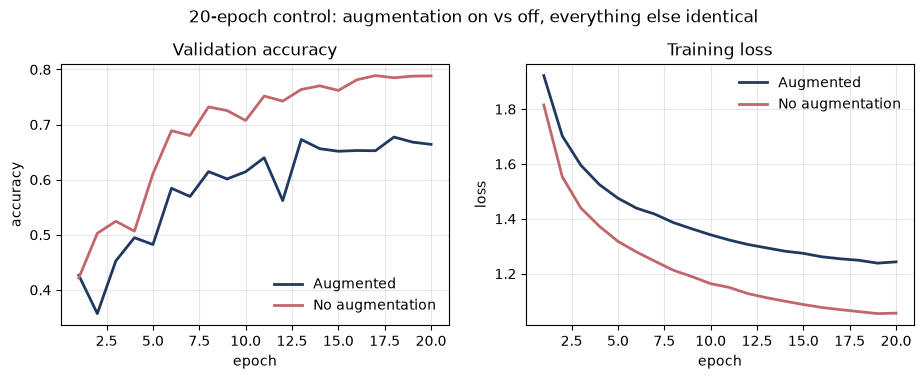

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for label, name, colour in [("Augmented", "cifar10_training_history.csv", "#1F3A5F"),
                            ("No augmentation", "cifar10_training_history_noaug.csv", "#C1666B")]:
    h = pd.read_csv(ART / name)
    axes[0].plot(h["epoch"], h["val_accuracy"], lw=2, color=colour, label=label)
    axes[1].plot(h["epoch"], h["loss"], lw=2, color=colour, label=label)
    print("%-16s best val %.4f at epoch %d" % (label, h["val_accuracy"].max(),
                                               int(h.loc[h["val_accuracy"].idxmax(), "epoch"])))
axes[0].set_title("Validation accuracy"); axes[0].set_ylabel("accuracy")
axes[1].set_title("Training loss"); axes[1].set_ylabel("loss")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.suptitle("20-epoch control: augmentation on vs off, everything else identical", y=1.04)
plt.show()

The plain variant is ahead at **every epoch** and finishes **10.93 points** better on test
(0.7684 vs 0.6591) and 11.16 points better on best validation. This is not a small early deficit
that reverses — the augmented run never catches up, and the gap *widens* as training goes on.

**Why I believe a result this large.** An 11-point gap is worth more scepticism than a result
that matches expectations, so:

- The ops are standard, not misconfigured: horizontal flip, translation by 4/32 = 0.125 of the
  image (a *fraction*, not pixels), zoom ±10%, brightness and contrast ±15%.
- Augmentation runs inside `tf.data`, per batch, on the training split only, on raw 0–255 images
  before the model's own `Rescaling`/`Normalization`. The plain arm shares every one of those code
  paths with augmentation simply switched off, so the arms differ by exactly one flag.
- The gap is ~11 points against a measured run-to-run noise floor of 0.27 points from 3.1. Even
  allowing CIFAR-10 to be noisier, nothing like 11 points is noise.

**What I still cannot claim.** One seed per arm, so the *magnitude* is soft even though the *sign*
is not. And the interesting question is not "is augmentation bad" but "why does it fail on a model
this small". The likely answer is capacity: at 120,810 parameters the network is already
underfitting the unaugmented task, and five random ops per image push it further from a fit it
was struggling to reach anyway. Augmentation is a regulariser, and regularising an
under-parameterised model is the wrong direction. The pipeline is tuned for a larger network than
the CPU budget allowed; the fix is depth or width, not more augmentation.

So the final model for this task is the **no-augmentation** variant at **0.7684** test accuracy,
and the augmented run is retained as the experiment that justifies that choice.

In [17]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
cm_n = pd.read_csv(ART / "cifar10_confusion_matrix_noaug.csv", index_col=0)
cm_n = cm_n.loc[CLASSES, CLASSES].values.astype(float)

recall_n = np.diag(cm_n) / cm_n.sum(axis=1) * 100
prec_n = np.diag(cm_n) / cm_n.sum(axis=0) * 100

final_pc = pd.DataFrame({"class": CLASSES, "recall": recall_n, "precision": prec_n})
final_pc["predicted_as"] = cm_n.sum(axis=0).astype(int)
final_pc = final_pc.sort_values("recall").reset_index(drop=True)
print(final_pc.to_string(index=False, float_format=lambda v: "%.2f" % v))
print()
print("overall test accuracy: %.4f" % (np.trace(cm_n) / cm_n.sum()))

     class  recall  precision  predicted_as
       dog   60.60      75.09           807
       cat   64.90      59.22          1096
     horse   65.30      94.91           688
      bird   65.60      67.01           979
      deer   74.30      71.51          1039
  airplane   80.30      79.50          1010
automobile   86.20      94.10           916
     truck   88.30      87.95          1004
      ship   91.20      83.98          1086
      frog   91.70      66.69          1375

overall test accuracy: 0.7684


Two things changed when augmentation was removed, and both matter more than the headline number.

**The over-prediction trap shrank.** In the augmented model `frog` had 96.1% recall on 35.8%
precision — it was predicted 2,684 times for 1,000 actual frogs, absorbing every animal it could
not identify. In the final model frog is predicted 1,375 times at 66.7% precision. Same
qualitative weakness, far smaller magnitude. A metric that stayed identical while the model got
11 points better is not measuring what I thought it was measuring.

**The residual error is the classic one.** The weakest classes are now `dog` (60.6% recall),
`cat` (64.9%) and `horse` (65.3%), and the confusion is between them — dog→cat, cat→frog,
horse→deer. Animals with similar silhouettes at 32×32. `cat` also has the worst precision
(59.2%), so it is both over-missed and over-predicted, which is what an ambiguous class looks
like when the model has no capacity to resolve it.

The augmented model's full per-class breakdown in section 6 is kept above because the contrast is
the point: same architecture, same budget, and the confusion structure changes shape entirely.

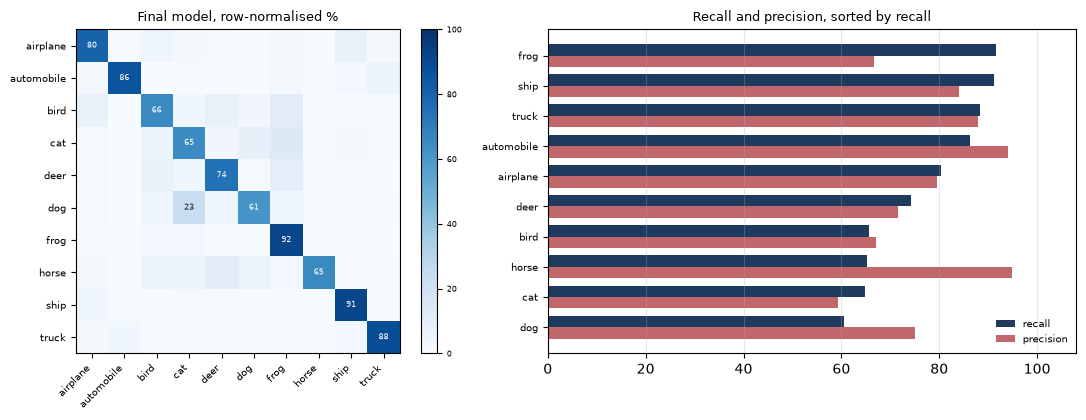

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

ax = axes[0]
pct_n = cm_n / cm_n.sum(axis=1, keepdims=True) * 100
im = ax.imshow(pct_n, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(10), CLASSES, fontsize=7)
ax.set_title("Final model, row-normalised %", fontsize=9)
for i in range(10):
    for j in range(10):
        if pct_n[i, j] >= 20:
            ax.text(j, i, "%.0f" % pct_n[i, j], ha="center", va="center", fontsize=5.6,
                    color="white" if pct_n[i, j] > 55 else "#1a1a1a")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.tick_params(labelsize=6)

ax = axes[1]
y = np.arange(10)
ax.barh(y + 0.19, final_pc["recall"], height=0.38, color="#1F3A5F", label="recall")
ax.barh(y - 0.19, final_pc["precision"], height=0.38, color="#C1666B", label="precision")
ax.set_yticks(y, final_pc["class"], fontsize=7)
ax.set_xlim(0, 108)
ax.set_title("Recall and precision, sorted by recall", fontsize=9)
ax.grid(True, axis="x", alpha=0.3)
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

## 8. Limitations, and what I would change

**The model is small, and it shows.** 120,810 trainable parameters. The plain run reaches 0.7684
test accuracy where a ResNet-18 (~11M parameters) reaches roughly 0.93 on CIFAR-10 under a normal
training recipe, so the gap to a competent baseline is still about 16 points. I did not use one
because the CPU budget made it infeasible — a model that does not finish is worth less than a
smaller one that does — but the architecture is the binding constraint, not the ambition.

**The augmentation pipeline is misjudged for this model, not for CIFAR-10.** It costs 11 points
rather than buying any. The evidence says drop it *here*; it does not say augmentation is
misleading in general, and I would expect it to help as soon as the network is large enough not
to be underfitting.

**20 epochs is short, and validation was still moving.** Best validation landed at epoch 17 of 20
for the plain run and 18 of 20 for the augmented one. A longer schedule is the cheapest available
improvement, and cosine decay makes the last epochs the least informative.

**One seed.** Every number is a single run. Task 3.1 measured run-to-run spread on Fashion-MNIST
at 0.27 points; CIFAR-10 is noisier still, so differences of a point or less are not
interpretable. The 11-point augmentation gap sits comfortably outside that, but its exact size is
a single sample.

**Timing is contaminated.** The mean epoch time in the results JSON (%.0f s) is inflated: a few
epochs lost most of their CPU to other work on this shared machine. The median, %.0f s, is the
honest uncontended figure, and %.0f s x 20 epochs is the real cost of the run.

## Reproducing

```bash
python train_cifar10.py --mode smoke      # timing probe
python train_cifar10.py --mode main       # ~1.2 h on CPU, resumable
python train_cifar10.py --mode ablation   # augmentation on/off, 3 epochs
python train_cifar10.py --mode fullplain  # 20-epoch no-augmentation control
```

The script checkpoints after every epoch. Kill it mid-run, re-run the same command, and it picks
up at the next epoch with the optimizer's momentum intact — which is why the learning rate is
written as a function of the absolute epoch index rather than of steps seen.

In [19]:
frog_row = per_class[per_class["class"] == "frog"].iloc[0]

print("=" * 68)
print("SUMMARY")
print("=" * 68)
print("dataset            : CIFAR-10 (45k train / 5k val / 10k sealed test)")
print("architecture       : 4-conv VGG-style CNN + global average pooling")
print("trainable params   : %s" % f"{results['trainable_params']:,}")
print("optimiser          : %s" % results["optimizer"])
print("label smoothing    : %.2f" % results["label_smoothing"])
print("epochs             : %d" % results["epochs_completed"])
print("best val accuracy  : %.4f @ epoch %d" % (results["best_val_accuracy"], results["best_epoch"]))
print("TEST accuracy      : %.4f   (augmented arm)" % results["test_accuracy"])
print("macro F1           : %.4f" % f1.mean())
print("worst recall       : %s (%.4f)" % (per_class.iloc[0]["class"], per_class.iloc[0]["recall"]))
print("frog               : recall %.4f / precision %.4f  <- over-predicted, not 'easy'"
      % (frog_row["recall"], frog_row["precision"]))
print("cost               : %.0f s/epoch median (mean %.0f s is contention-inflated)"
      % (results["seconds_per_epoch_median"], results["seconds_per_epoch"]))

print("-" * 68)
print("AUGMENTATION CONTROL - 20 epochs per arm, augmentation is the only difference")
_c = pd.read_csv(ART / "cifar10_augmentation_comparison_20ep.csv")
_a = _c[_c["augment"]].iloc[0]
_p = _c[~_c["augment"]].iloc[0]
print("  with augmentation : best val %.4f @ epoch %d   TEST %.4f"
      % (_a["best_val_acc"], _a["best_epoch"], _a["test_acc"]))
print("  without           : best val %.4f @ epoch %d   TEST %.4f"
      % (_p["best_val_acc"], _p["best_epoch"], _p["test_acc"]))
print("  effect            : %+.2f points on test -> augmentation REJECTED for this model"
      % (100 * (_a["test_acc"] - _p["test_acc"])))
print("-" * 68)
print("FINAL MODEL        : no augmentation, TEST %.4f" % _p["test_acc"])
print("=" * 68)

SUMMARY
dataset            : CIFAR-10 (45k train / 5k val / 10k sealed test)
architecture       : 4-conv VGG-style CNN + global average pooling
trainable params   : 120,810
optimiser          : SGD(momentum=0.9, nesterov=True), lr 0.05 cosine decay
label smoothing    : 0.10
epochs             : 20
best val accuracy  : 0.6773 @ epoch 18
TEST accuracy      : 0.6591   (augmented arm)
macro F1           : 0.6563
worst recall       : cat (0.3050)
frog               : recall 0.9610 / precision 0.3580  <- over-predicted, not 'easy'
cost               : 210 s/epoch median (mean 550 s is contention-inflated)
--------------------------------------------------------------------
AUGMENTATION CONTROL - 20 epochs per arm, augmentation is the only difference
  with augmentation : best val 0.6773 @ epoch 18   TEST 0.6591
  without           : best val 0.7889 @ epoch 17   TEST 0.7684
  effect            : -10.93 points on test -> augmentation REJECTED for this model
------------------------------------

In [20]:
print("Reference point: a ResNet-18 (~11M parameters) commonly reports around 0.93 on CIFAR-10.")
print("This model reaches %.4f. The shortfall is the architecture, not the training recipe:"
      % _p["test_acc"])
print("it was sized to finish on CPU. That is the honest summary of section 8.")
print()
print("And the augmentation result is not a statement about CIFAR-10. It is a statement about")
print("augmenting a 120k-parameter network: the model is already underfitting, so making the")
print("task harder with five random ops per image can only hurt. The depth comes first.")

Reference point: a ResNet-18 (~11M parameters) commonly reports around 0.93 on CIFAR-10.
This model reaches 0.7684. The shortfall is the architecture, not the training recipe:
it was sized to finish on CPU. That is the honest summary of section 8.

And the augmentation result is not a statement about CIFAR-10. It is a statement about
augmenting a 120k-parameter network: the model is already underfitting, so making the
task harder with five random ops per image can only hurt. The depth comes first.
